# 真实 CT DICOM：像素、HU 与窗宽窗位

本课从随项目提供的公开 DICOM 原图开始，不生成合成 CT。示例用于理解医学图像像素重标定和显示窗，不作诊断。

C:\Users\De\.conda\envs\pyg\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (6.0.0.post1)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


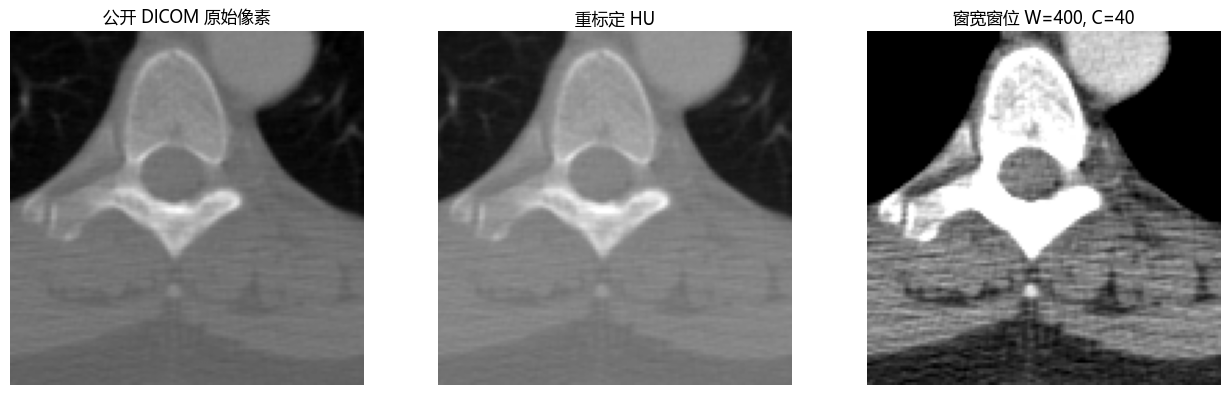

文件: CT_small.dcm 模态: CT 矩阵: (128, 128) HU范围: -896.0 1167.0
这是公开教学 DICOM，不是合成示意图；仅用于图像处理演示，不作临床诊断。


In [1]:
from pathlib import Path
import numpy as np, matplotlib.pyplot as plt, pydicom
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "courses/industrial-vision-lab/data/public/medical/CT_small.dcm").exists())
import sys
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from course_utils import configure_plot_fonts
configure_plot_fonts()
path = ROOT / "courses/industrial-vision-lab/data/public/medical/CT_small.dcm"
ds = pydicom.dcmread(path); stored = ds.pixel_array.astype(np.float32)
hu = stored * float(getattr(ds, "RescaleSlope", 1)) + float(getattr(ds, "RescaleIntercept", 0))
center, width = 40, 400
window = np.clip((hu-(center-width/2))/width, 0, 1)
fig, axs = plt.subplots(1, 3, figsize=(13, 4)); axs[0].imshow(stored, cmap="gray"); axs[0].set_title("公开 DICOM 原始像素"); axs[1].imshow(hu, cmap="gray", vmin=-1000, vmax=1000); axs[1].set_title("重标定 HU"); axs[2].imshow(window, cmap="gray", vmin=0, vmax=1); axs[2].set_title(f"窗宽窗位 W={width}, C={center}");
for ax in axs: ax.axis("off")
plt.tight_layout(); plt.show()
print("文件:", path.name, "模态:", ds.Modality, "矩阵:", hu.shape, "HU范围:", float(hu.min()), float(hu.max()))
print("这是公开教学 DICOM，不是合成示意图；仅用于图像处理演示，不作临床诊断。")